# Task 4.2


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
FAST = True


In [2]:
def leg(x, q):
    x = np.asarray(x, dtype=float)
    z = np.zeros(x.shape + (q + 1,))
    z[..., 0] = 1
    if q > 0:
        z[..., 1] = x
    for k in range(2, q + 1):
        z[..., k] = ((2*k - 1)*x*z[..., k-1] - (k-1)*z[..., k-2]) / k
    return z


def gen(n, q, v, r, rng):
    a = rng.normal(size=(r, q + 1))
    s = np.sqrt(np.sum(a**2 / (2*np.arange(q + 1) + 1), axis=1))
    a = a / s[:, None]
    x = rng.uniform(-1, 1, size=(r, n))
    y = np.sum(leg(x, q) * a[:, None, :], axis=2)
    y = y + np.sqrt(v) * rng.normal(size=(r, n))
    return x, y, a


def eout(a, w, v=0):
    p = max(a.shape[-1], w.shape[-1])
    aa = np.zeros(a.shape[:-1] + (p,))
    ww = np.zeros(w.shape[:-1] + (p,))
    aa[..., :a.shape[-1]] = a
    ww[..., :w.shape[-1]] = w
    return v + np.sum((ww - aa)**2 / (2*np.arange(p) + 1), axis=-1)


def stat(x, axis=0):
    x = np.asarray(x)
    return x.mean(axis=axis), x.std(axis=axis, ddof=1) / np.sqrt(x.shape[axis])


def ridge(z, y, ls):
    ls = np.asarray(ls, dtype=float)
    u, s, vt = np.linalg.svd(z, full_matrices=False)
    d = s[None, :]**2 + ls[:, None]
    t = np.divide(s[None, :], d, out=np.zeros_like(d), where=d > 0)
    eps = np.finfo(float).eps * max(z.shape) * s[0]
    t[(ls[:, None] == 0) & (s[None, :] <= eps)] = 0
    w = (t * (u.T @ y)) @ vt
    h = (t * s) @ (u**2).T
    return w, h


In [3]:
R = 200 if FAST else 500
ls = np.r_[0, np.logspace(-4, 2, 41)]
cs = [(15, 0), (15, 0.25), (15, 0.5), (15, 1.0), (30, 0)]
rng = np.random.default_rng(407)
ei = np.empty((len(cs), R, len(ls)))
eo = np.empty_like(ei)
df = np.empty_like(ei)

for i, (q, v) in enumerate(cs):
    x, y, a = gen(30, q, v, R, rng)
    for r in range(R):
        z = leg(x[r], 10)
        w, h = ridge(z, y[r], ls)
        ei[i, r] = np.mean((z @ w.T - y[r, :, None]) ** 2, axis=0)
        eo[i, r] = eout(a[r], w, v)
        df[i, r] = h.sum(axis=1)
    print(f"Completed Qf={q}, variance={v}")

mi, si = stat(ei, axis=1)
mo, so = stat(eo, axis=1)
b = np.argmin(mo, axis=1)


Completed Qf=15, variance=0
Completed Qf=15, variance=0.25
Completed Qf=15, variance=0.5
Completed Qf=15, variance=1.0
Completed Qf=30, variance=0


Qf=15, variance=0: lambda*=0.5623; Eout=0.23643 +/- 0.0122 SE, n=200
Qf=15, variance=0.25: lambda*=0.7943; Eout=0.50095 +/- 0.00937 SE, n=200
Qf=15, variance=0.5: lambda*=1.585; Eout=0.8455 +/- 0.0128 SE, n=200
Qf=15, variance=1.0: lambda*=2.239; Eout=1.4333 +/- 0.0146 SE, n=200
Qf=30, variance=0: lambda*=0.7943; Eout=0.40232 +/- 0.0143 SE, n=200


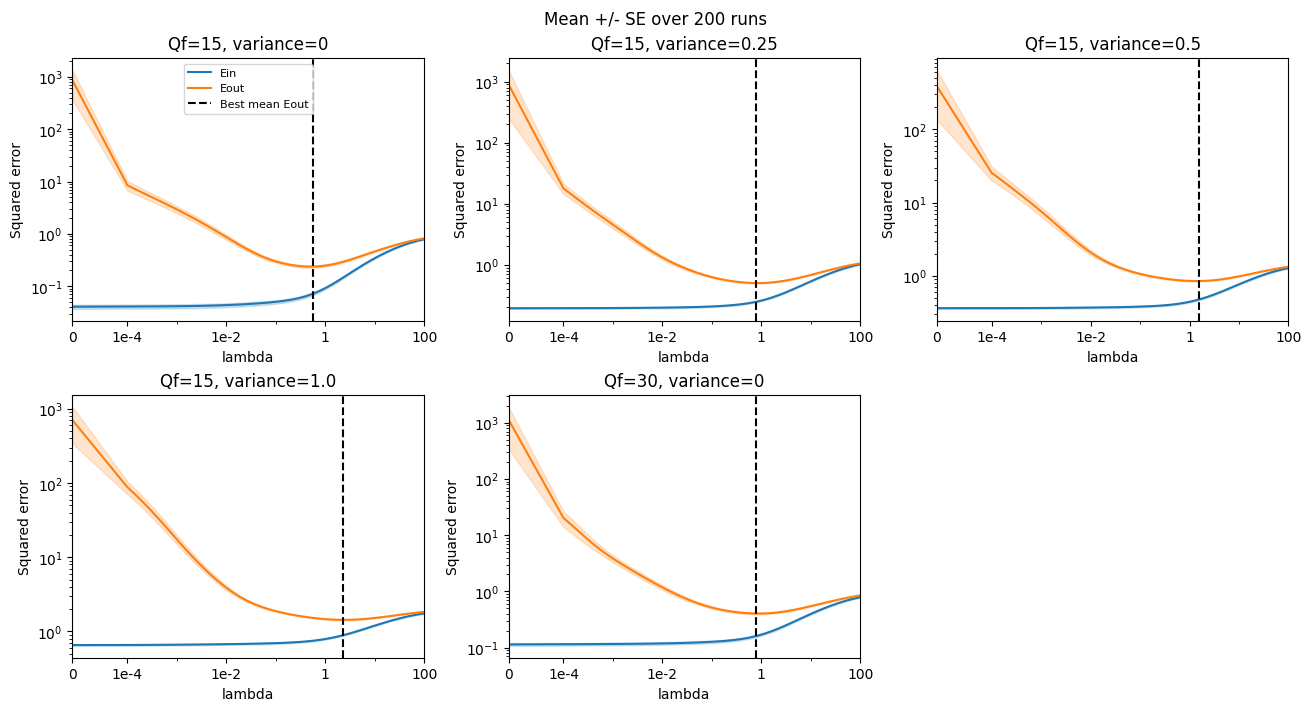

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for i, (q, v) in enumerate(cs):
    ax = axs.flat[i]
    for m, se, lab in [(mi[i], si[i], "Ein"),
                            (mo[i], so[i], "Eout")]:
        line, = ax.plot(ls, m, label=lab)
        ax.fill_between(ls, np.maximum(m - se, 1e-12), m + se,
                        color=line.get_color(), alpha=0.2)
    ax.axvline(ls[b[i]], color="black", linestyle="--", label="Best mean Eout")
    ax.set_xscale("symlog", linthresh=1e-4)
    ax.set_xlim(0, ls[-1])
    ax.set_xticks([0, 1e-4, 1e-2, 1, 100], ["0", "1e-4", "1e-2", "1", "100"])
    ax.set_yscale("log")
    ax.set(xlabel="lambda", ylabel="Squared error", title=f"Qf={q}, variance={v}")
    print(f"Qf={q}, variance={v}: lambda*={ls[b[i]]:.4g}; "
          f"Eout={mo[i, b[i]]:.5g} +/- {so[i, b[i]]:.3g} SE, n={R}")
axs.flat[0].legend(fontsize=8)
axs.flat[5].axis("off")
fig.suptitle(f"Mean +/- SE over {R} runs")
plt.show()


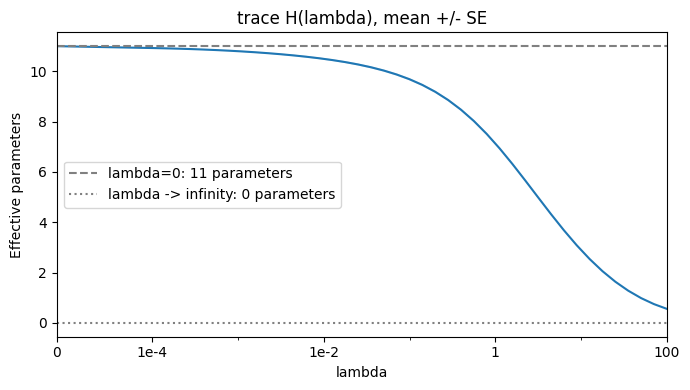

In [5]:
m, se = stat(df[0])
assert np.allclose(df[:, :, 0], 11, atol=1e-8)
_, h_large = ridge(z, y[-1], [1e12])
assert h_large.sum() < 1e-6
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ls, m)
ax.fill_between(ls, m - se, m + se, alpha=0.2)
ax.axhline(11, linestyle="--", color="grey", label="lambda=0: 11 parameters")
ax.axhline(0, linestyle=":", color="grey", label="lambda -> infinity: 0 parameters")
ax.set_xscale("symlog", linthresh=1e-4)
ax.set_xlim(0, ls[-1])
ax.set_xticks([0, 1e-4, 1e-2, 1, 100], ["0", "1e-4", "1e-2", "1", "100"])
ax.set(xlabel="lambda", ylabel="Effective parameters", title="trace H(lambda), mean +/- SE")
ax.legend()
fig.tight_layout()
plt.show()


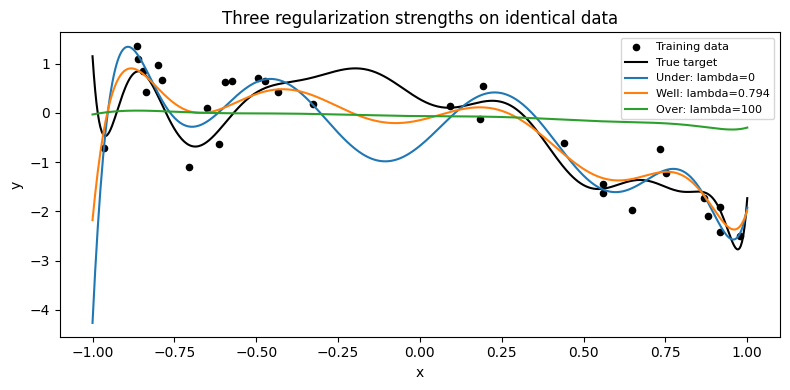

In [6]:
rng0 = np.random.default_rng(407 + 1)
x, y, a = gen(30, 15, 0.25, 1, rng0)
ls0 = [0, ls[b[1]], 100]
w, _ = ridge(leg(x[0], 10), y[0], ls0)
grid = np.linspace(-1, 1, 500)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x[0], y[0], color="black", s=20, label="Training data")
ax.plot(grid, leg(grid, 15) @ a[0], color="black", label="True target")
for w, lam, lab in zip(w, ls0, ["Under", "Well", "Over"]):
    ax.plot(grid, leg(grid, 10) @ w, label=f"{lab}: lambda={lam:.3g}")
ax.set(xlabel="x", ylabel="y", title="Three regularization strengths on identical data")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
